# Prediksi Harga Rumah Melbourne

Dataset: Melbourne Housing Snapshot
Sumber: https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot

Target prediksi: kolom Price

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv('melb_data.csv')
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## 1. Data Wrangling dan EDA

In [3]:
df.shape

(13580, 21)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [5]:
df.isnull().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [6]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


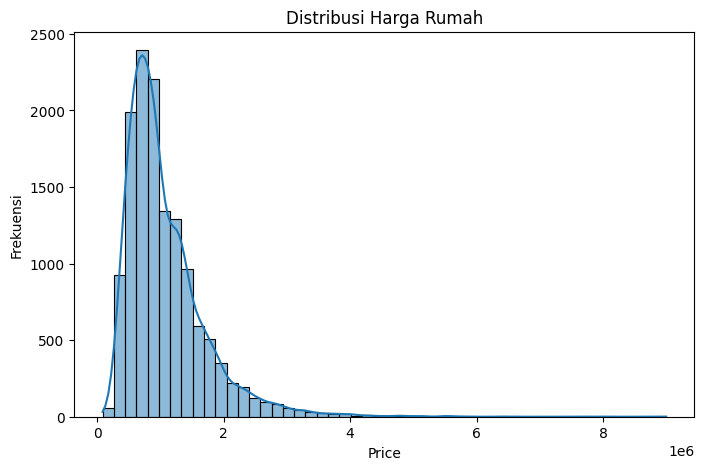

In [7]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], bins=50, kde=True)
plt.title('Distribusi Harga Rumah')
plt.xlabel('Price')
plt.ylabel('Frekuensi')
plt.show()

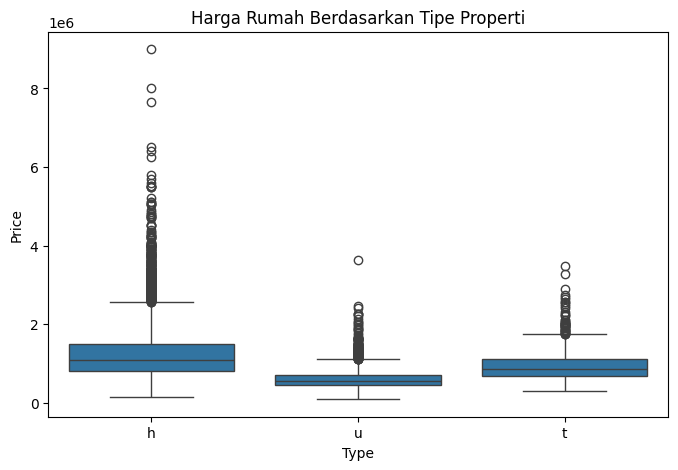

In [8]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Type', y='Price', data=df)
plt.title('Harga Rumah Berdasarkan Tipe Properti')
plt.show()

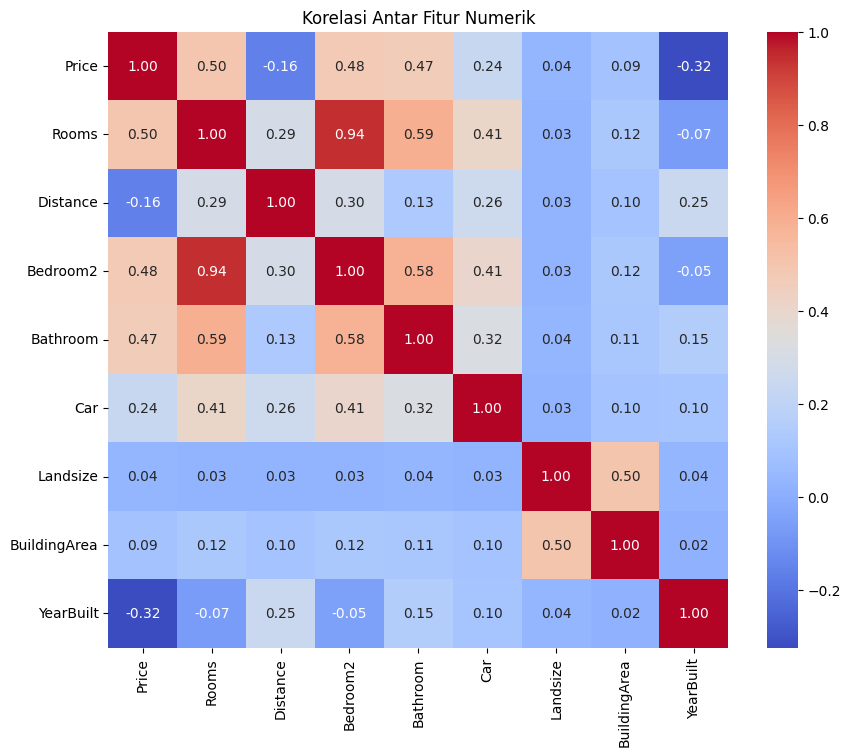

In [9]:
plt.figure(figsize=(10,8))
num_cols = ['Price','Rooms','Distance','Bedroom2','Bathroom','Car','Landsize','BuildingArea','YearBuilt']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Korelasi Antar Fitur Numerik')
plt.show()

## 2. Data Cleaning

In [10]:
df_clean = df.copy()

df_clean['Car'] = df_clean['Car'].fillna(df_clean['Car'].median())
df_clean['BuildingArea'] = df_clean['BuildingArea'].fillna(df_clean['BuildingArea'].median())
df_clean['YearBuilt'] = df_clean['YearBuilt'].fillna(df_clean['YearBuilt'].median())
df_clean['CouncilArea'] = df_clean['CouncilArea'].fillna('Unknown')

df_clean.isnull().sum()

,0
Suburb,0
Address,0
Rooms,0
Type,0
Price,0
Method,0
SellerG,0
Date,0
Distance,0
Postcode,0


In [11]:
# Hapus outlier ekstrem pada Price dan Landsize pakai metode IQR
def remove_outlier(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    return data[(data[col] >= lower) & (data[col] <= upper)]

df_clean = remove_outlier(df_clean, 'Price')
df_clean = remove_outlier(df_clean, 'Landsize')
df_clean = remove_outlier(df_clean, 'BuildingArea')
df_clean.shape

(7451, 21)

In [12]:
df_clean = df_clean.drop(columns=['Address','Date','SellerG','Postcode','Suburb'])
df_clean = df_clean.reset_index(drop=True)
df_clean.head()

,Rooms,Type,Price,Method,Distance,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,2,h,1480000.0,S,2.5,2.0,1.0,1.0,202.0,126.0,1970.0,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,3,h,850000.0,PI,2.5,3.0,2.0,1.0,94.0,126.0,1970.0,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
2,2,h,941000.0,S,2.5,2.0,1.0,0.0,181.0,126.0,1970.0,Yarra,-37.8041,144.9953,Northern Metropolitan,4019.0
3,1,u,300000.0,S,2.5,1.0,1.0,1.0,0.0,126.0,1970.0,Yarra,-37.8008,144.9973,Northern Metropolitan,4019.0
4,2,u,700000.0,VB,2.5,2.0,2.0,1.0,0.0,126.0,1970.0,Yarra,-37.8110,145.0067,Northern Metropolitan,4019.0


## 3. Machine Learning Pipeline

In [13]:
features = ['Rooms','Type','Distance','Bedroom2','Bathroom','Car','Landsize',
            'BuildingArea','YearBuilt','Regionname','CouncilArea',
            'Lattitude','Longtitude','Propertycount']
target = 'Price'

X = df_clean[features]
y = df_clean[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_features = ['Rooms','Distance','Bedroom2','Bathroom','Car','Landsize','BuildingArea',
                'YearBuilt','Lattitude','Longtitude','Propertycount']
cat_features = ['Type','Regionname','CouncilArea']

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

In [14]:
# Tuning Linear Regression pakai Ridge supaya ada parameter regularisasi yang dituning
from sklearn.linear_model import Ridge

pipe_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

param_grid_lr = {
    'model__alpha': [0.01, 0.1, 1, 10, 50, 100]
}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=5, scoring='r2', n_jobs=-1)
grid_lr.fit(X_train, y_train)

print('Parameter terbaik Linear Regression (Ridge):', grid_lr.best_params_)
best_lr = grid_lr.best_estimator_
pred_lr = best_lr.predict(X_test)

Parameter terbaik Linear Regression (Ridge): {'model__alpha': 1}


In [15]:
# Tuning Decision Tree Regressor dengan grid lebih luas
from sklearn.model_selection import RandomizedSearchCV

pipe_dt = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

param_grid_dt = {
    'model__max_depth': [8, 10, 12, 15, 18, 20, None],
    'model__min_samples_split': [2, 5, 10, 20],
    'model__min_samples_leaf': [1, 2, 4, 8],
    'model__max_features': [None, 'sqrt']
}

grid_dt = RandomizedSearchCV(
    pipe_dt, param_grid_dt, n_iter=40, cv=5, scoring='r2',
    n_jobs=-1, random_state=42
)
grid_dt.fit(X_train, y_train)

print('Parameter terbaik Decision Tree:', grid_dt.best_params_)
best_dt = grid_dt.best_estimator_
pred_dt = best_dt.predict(X_test)

Parameter terbaik Decision Tree: {'model__min_samples_split': 20, 'model__min_samples_leaf': 8, 'model__max_features': None, 'model__max_depth': 15}


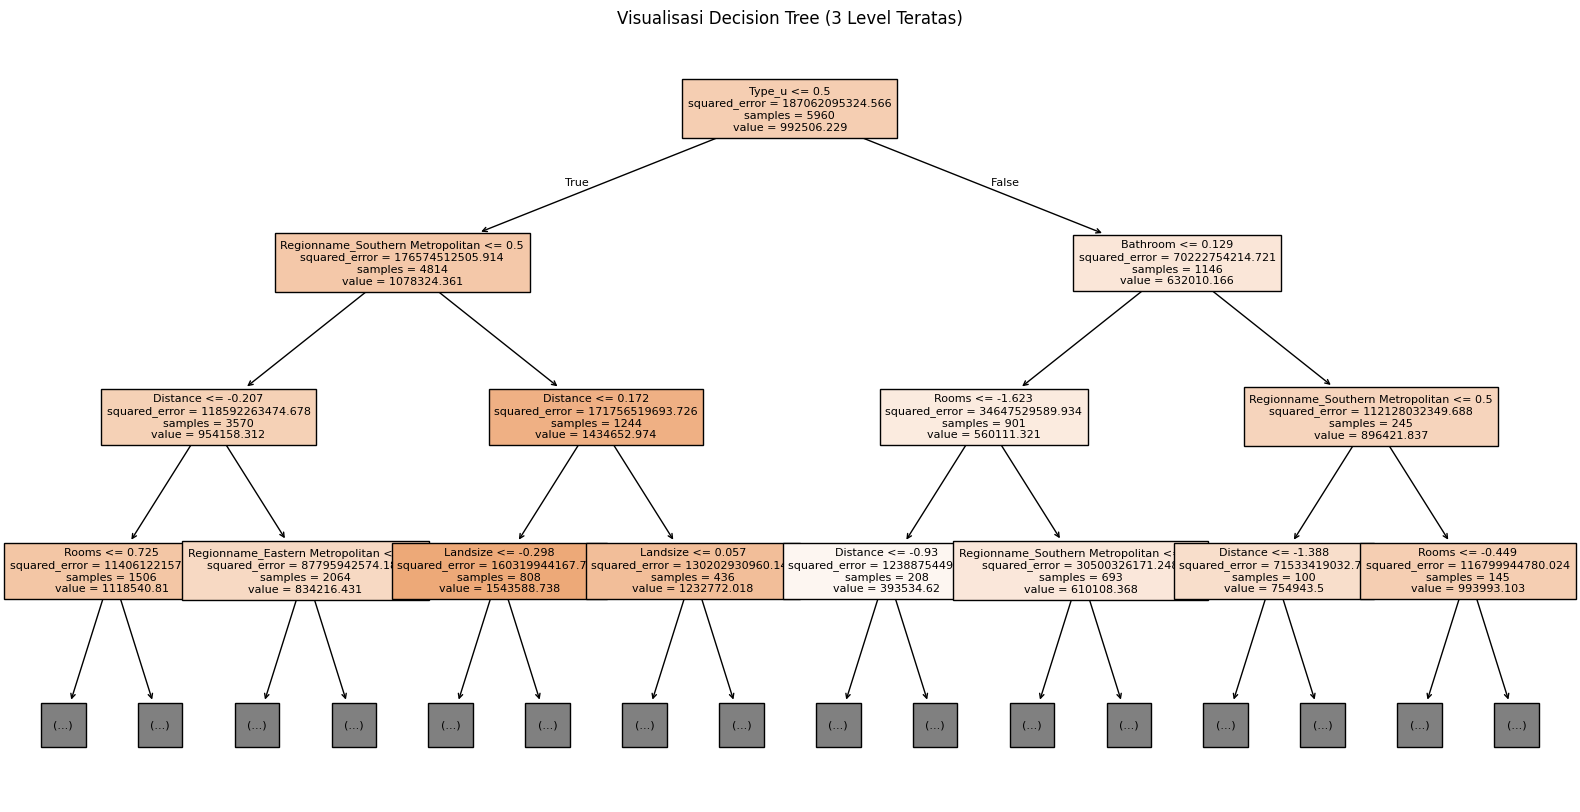

In [ ]:
from sklearn.tree import plot_tree

feature_names = num_features + list(
    best_dt.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_features)
)

plt.figure(figsize=(24,14))   # tadinya (20,10), dibikin lebih tinggi
plot_tree(
    best_dt.named_steps['model'],
    max_depth=3,
    feature_names=feature_names,
    filled=True,
    fontsize=9
)
plt.title('Visualisasi Decision Tree (3 Level Teratas)')
plt.tight_layout()
plt.show()

## 4. Evaluasi Model

In [17]:
def evaluate(y_true, y_pred, name):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f'{name}')
    print(f'R2   : {r2:.4f}')
    print(f'RMSE : {rmse:,.2f}')
    print()
    return r2, rmse

r2_lr, rmse_lr = evaluate(y_test, pred_lr, 'Linear Regression (Ridge, Tuned)')
r2_dt, rmse_dt = evaluate(y_test, pred_dt, 'Decision Tree Regressor (Tuned)')

Linear Regression (Ridge, Tuned)
R2   : 0.6355
RMSE : 261,178.97

Decision Tree Regressor (Tuned)
R2   : 0.7017
RMSE : 236,282.35



## 5. Simulasi Prediksi Data Baru

In [18]:
# Tentukan model terbaik berdasarkan R2 tertinggi
if r2_dt > r2_lr:
    model_terbaik = best_dt
    nama_model = 'Decision Tree Regressor'
else:
    model_terbaik = best_lr
    nama_model = 'Linear Regression (Ridge)'

print('Model terbaik:', nama_model)

Model terbaik: Decision Tree Regressor


In [19]:
# Data baru kustom untuk simulasi prediksi
data_baru = pd.DataFrame({
    'Rooms': [3],
    'Type': ['h'],
    'Distance': [5.0],
    'Bedroom2': [3],
    'Bathroom': [2],
    'Car': [1],
    'Landsize': [400],
    'BuildingArea': [150],
    'YearBuilt': [2005],
    'Regionname': ['Northern Metropolitan'],
    'CouncilArea': ['Yarra'],
    'Lattitude': [-37.80],
    'Longtitude': [144.99],
    'Propertycount': [4019]
})

prediksi_harga = model_terbaik.predict(data_baru)
print(f'Prediksi harga rumah: AUD {prediksi_harga[0]:,.2f}')

Prediksi harga rumah: AUD 1,239,431.82


# 6. Eksport Ke File xlsx

In [20]:
df_clean.to_excel('melb_data_clean.xlsx', index=False)
print('File berhasil disimpan: melb_data_clean.xlsx')

File berhasil disimpan: melb_data_clean.xlsx
